# Next Frame — Movie Recommendation Engine

B.Y.T.E Data Science Task 7. Biased matrix factorization, baseline comparison, known-user recommendations and a new-visitor rating flow. MovieLens 32M ratings end in October 2023; no 2026 coverage is claimed.

In [1]:
import json, inspect
from pathlib import Path
import pandas as pd
import numpy as np
from IPython.display import display, Image
source=json.loads(Path("data/source.json").read_text())
source

{'source': 'https://files.grouplens.org/datasets/movielens/ml-32m.zip',
 'dataset': 'MovieLens 32M',
 'ratings_end': '2023-10-12',
 'retrieved_or_verified_at_utc': '2026-10-02T14:06:55.374171+00:00',
 'sample_users': 5000,
 'sample_seed': 42,
 'sample_ratings': 779802,
 'source_ratings_md5': 'cf12b74f9ad4b94a011f079e26d4270a',
 'sample_sha256': '5ae4c1c949b1900cea380288c3d2faf4bdb493e30ffe2575fc5e81e62b033297',
 'split': 'Per-user chronological 80/10/10; not a global prospective time split',
 'split_counts': {'train': 621912, 'test': 80235, 'validation': 77655}}

## Preprocessing and split

Uniformly sample 5,000 users with seed 42. Validate published source checksums, sort each user by timestamp with movie-ID tie breaking, and split 80/10/10 into training, validation and test ratings. This is per-user chronological evaluation, not a global prospective simulation. User/item mappings and popularity support come only from training. Missing ratings are never filled with zero.

In [2]:
import prepare
print(inspect.getsource(prepare.prepare))
df=pd.read_csv("data/ratings_sample.csv")
display(df.groupby("split").agg(ratings=("rating","size"),users=("userId","nunique"),movies=("movieId","nunique")))
from verify import verify
verify()

def prepare(users=5000,seed=42):
    data=ROOT/'data';data.mkdir(exist_ok=True)
    path=data/'ml-32m.zip'
    if not path.exists():
        temp=path.with_suffix('.part')
        with urlopen(URL,timeout=120) as response,temp.open('wb') as f:
            while block:=response.read(1024*1024):f.write(block)
        temp.replace(path)
    with zipfile.ZipFile(path) as z:
        # Published user identifiers are contiguous 1..200948. Seeded uniform user sampling.
        ids=set(np.random.default_rng(seed).choice(np.arange(1,200949),users,replace=False).tolist())
        chunks=[];digest=hashlib.md5()
        with z.open('ml-32m/ratings.csv') as f:
            while block:=f.read(1024*1024):digest.update(block)
        assert digest.hexdigest()=='cf12b74f9ad4b94a011f079e26d4270a','Ratings checksum mismatch'
        with z.open('ml-32m/ratings.csv') as f:
            for chunk in pd.read_csv(f,chunksize=1000000):chunks.append(chunk[chunk.userId.isin(ids)])
        ratings=pd.concat(chunks

,ratings,users,movies
split,,,
test,80235,5000,12308
train,621912,5000,19615
validation,77655,5000,11654


Verified rating-pair uniqueness and chronological split ordering for every sampled user.


## Model training

Estimate rating = global mean + user bias + movie bias + dot product of latent factors. Minimize observed-rating squared error with L2 regularization using stochastic gradient descent. Compare four settings and retain the lowest validation RMSE checkpoint, with a maximum of 25 epochs. The baseline fits regularized user/movie biases without latent factors. Predictions are clipped to 0.5–5 stars. Unseen test movies use the user-bias fallback.

This notebook displays the exact training source and recorded results to avoid rerunning the search every time it is opened. Run `python train.py` to reproduce fitting, then `python evaluate_ranking.py`, `python tune_ranking.py`, `python export_ranking.py` and `python make_notebook.py` to refresh all results.

In [3]:
import model, train
print(inspect.getsource(model))
print(inspect.getsource(train.train))
display(pd.read_csv("outputs/candidate_results.csv"))

"""Biased matrix factorization trained only on observed ratings."""
import numpy as np
from numba import njit

@njit(cache=True)
def epoch(u,i,r,order,mu,bu,bi,P,Q,lr,reg):
    for row in order:
        a,b=u[row],i[row];estimate=mu+bu[a]+bi[b]
        for k in range(P.shape[1]):estimate+=P[a,k]*Q[b,k]
        error=r[row]-estimate
        bu[a]+=lr*(error-reg*bu[a]);bi[b]+=lr*(error-reg*bi[b])
        for k in range(P.shape[1]):
            old=P[a,k];P[a,k]+=lr*(error-reg*old);Q[b,k]+=lr*(error*old-reg*Q[b,k])

def predict(mu,bu,bi,P,Q,u,i):
    valid=i>=0;result=mu+bu[u]
    result=result.copy();result[valid]+=bi[i[valid]]+np.sum(P[u[valid]]*Q[i[valid]],axis=1)
    return np.clip(result,.5,5)

def metrics(actual,pred):
    return {'rmse':float(np.sqrt(np.mean((actual-pred)**2))),'mae':float(np.mean(np.abs(actual-pred)))}

def top_five(mu,bu,bi,P,Q,user,seen,eligible,counts=None,support_weight=None):
    raw=mu+bu[user]+bi+Q@P[user]
    estimates=np.clip(raw,.5,5)
    scores=estimate

,factors,regularization,best_epoch,validation_rmse
0,16,0.05,4,0.859385
1,32,0.05,2,0.862138
2,32,0.15,2,0.864627
3,48,0.10,4,0.864594


## Evaluation

Test metrics are calculated after selecting settings on validation. Ranking metrics use a fixed seeded sample of 200 users with held-out ratings >=4. Unobserved items are not necessarily disliked; these ranking metrics use incomplete observed relevance. Ranking and rating-error baselines differ and are labeled separately. The published errors describe established users, not the onboarding flow.

,rmse,mae
baseline,0.883342,0.669561
factor_model,0.879372,0.664517


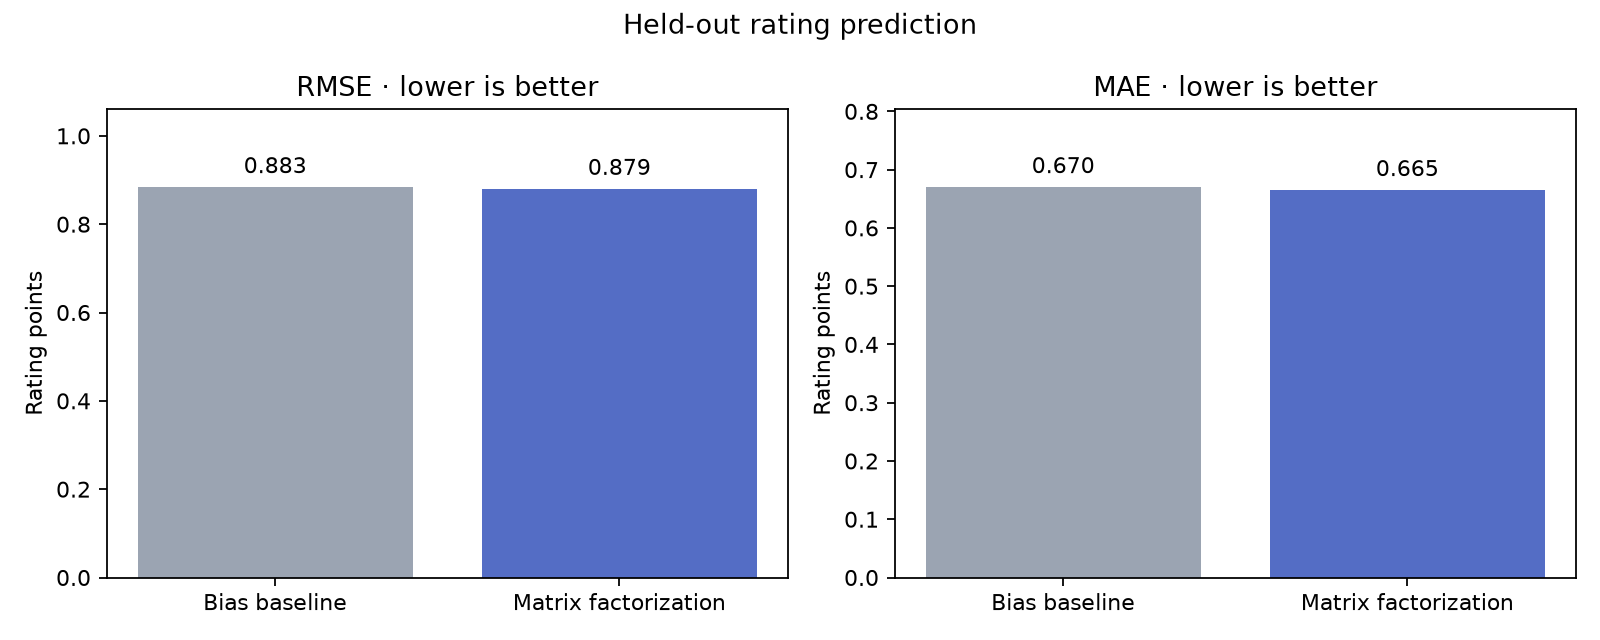

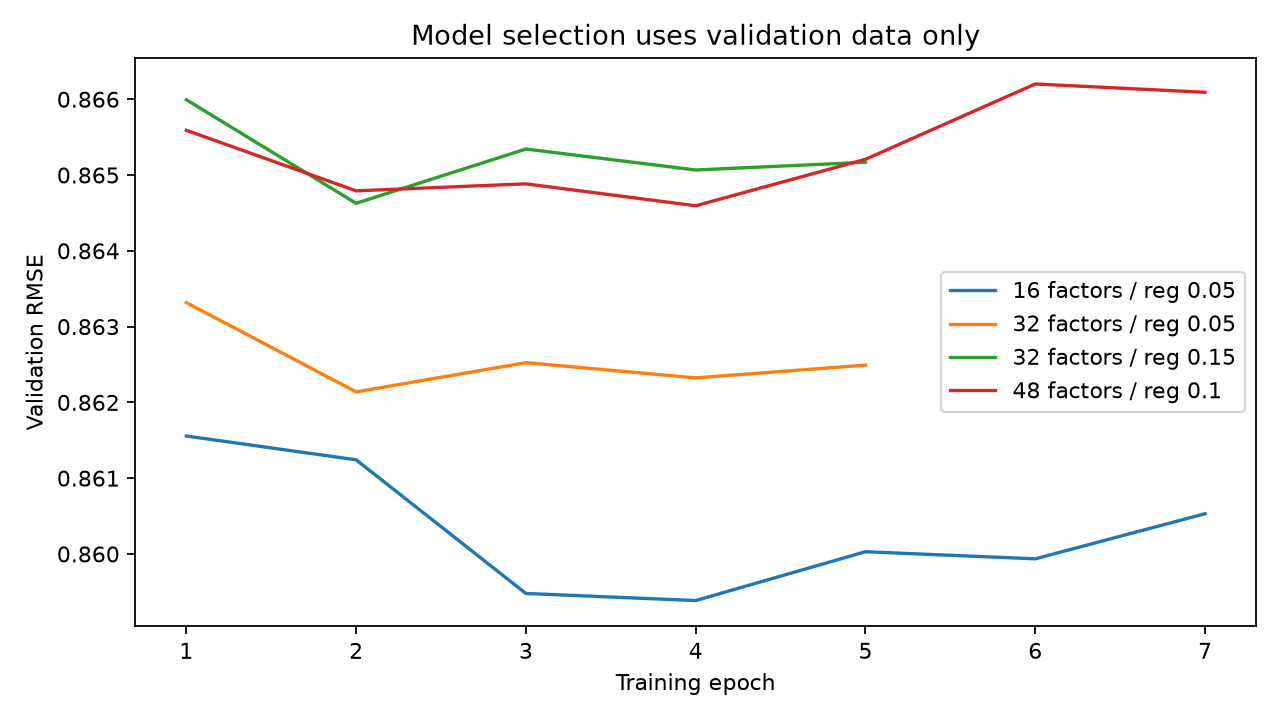

{'users': 200,
 'seed': 2026,
 'relevance': 'Held-out rating >=4; only users with at least one such rating. Unknown/unrated items have unknown relevance.',
 'candidate_policy': 'All movies with >=20 training ratings; excludes training and validation history. Unknown test movies remain in recall denominator.',
 'metrics': {'factor_model': {'precision_at_5': 0.009000000000000001,
   'recall_at_5': 0.0075264319014319014,
   'ndcg_at_5': 0.008629694494274748},
  'movie_average': {'precision_at_5': 0.024000000000000004,
   'recall_at_5': 0.016620526168344307,
   'ndcg_at_5': 0.029859503545631626}}}

In [4]:
metrics=json.loads(Path("outputs/metrics.json").read_text())
display(pd.DataFrame({k:metrics[k] for k in ["baseline","factor_model"]}).T)
display(Image(filename="outputs/evaluation.png"))
display(Image(filename="outputs/learning_curves.png"))
json.loads(Path("outputs/ranking_metrics.json").read_text())

## Improving top-five ranking while keeping matrix factorization

The deployed ranking score adds a validation-selected weight times log(1 + training rating count) to the unclipped MF estimate. Displayed predicted stars remain clipped to 0.5–5. This is a support/popularity adjustment, not a newly trained factor model. Select among seven predeclared weights using mean NDCG@5 on 500 validation users, then freeze before evaluating test.

All methods use the same candidate pool and exclusions. Compare with original MF, Bayesian movie averages and a strong most-rated baseline. The historical test cohort was already examined earlier, so this is not a new untouched benchmark. Increased popularity can reduce novelty. The new-visitor flow has not been separately evaluated.

"""Select a support-aware MF ranker on validation only; freeze before test audits.

This improves the serving objective without pretending ranking scores are stars.
Historical test results are reused for comparison, not a new untouched benchmark.
"""
from pathlib import Path
import json, os
import numpy as np
import pandas as pd
ROOT=Path(__file__).resolve().parent
os.environ.setdefault('MPLCONFIGDIR',str(ROOT/'.runtime/matplotlib'))

def measure(scores, allowed, truth, ids):
    values=np.where(allowed,scores,-np.inf)
    top=np.argsort(-values,kind='stable')[:5]
    chosen=[int(ids[j]) for j in top if np.isfinite(values[j])]
    hit=[int(mid in truth) for mid in chosen]
    ideal=sum(1/np.log2(k+2) for k in range(min(5,len(truth))))
    return [sum(hit)/5,sum(hit)/len(truth),sum(v/np.log2(k+2) for k,v in enumerate(hit))/ideal]

def run():
    s=np.load(ROOT/'outputs/model.npz',allow_pickle=False)
    df=pd.read_csv(ROOT/'data/ratings_sample.csv');ids=s['items'];im={int(x):j for j,x i

,precision_at_5,recall_at_5,ndcg_at_5
most_rated,0.0352,0.033185,0.042989
movie_average,0.0168,0.017333,0.022346
original,0.0060,0.004328,0.006485
weight_0,0.0060,0.004328,0.006485
weight_0.05,0.0160,0.015676,0.020685
weight_0.1,0.0268,0.025257,0.032024
weight_0.2,0.0308,0.031940,0.037725
weight_0.4,0.0328,0.032687,0.040522
weight_0.8,0.0336,0.029038,0.040867
weight_1.6,0.0344,0.032062,0.042088


,precision_at_5,recall_at_5,ndcg_at_5
improved,0.039,0.033860,0.054622
most_rated,0.035,0.034966,0.051715
movie_average,0.024,0.016621,0.029860
original,0.009,0.007526,0.008630


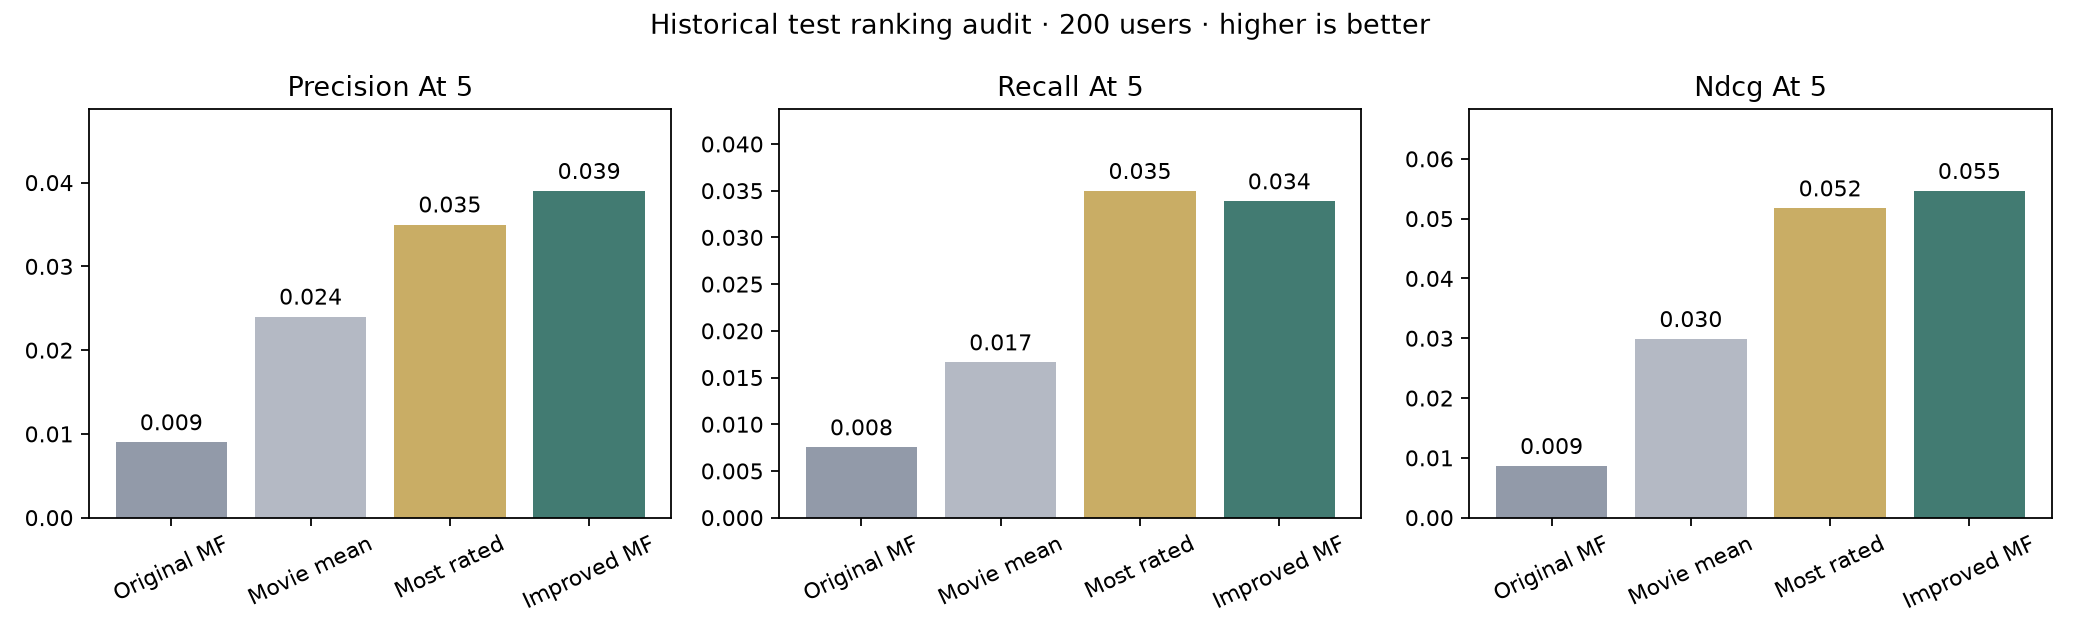

In [5]:
import tune_ranking
print(inspect.getsource(tune_ranking))
upgrade=json.loads(Path("outputs/ranking_improvement.json").read_text())
display(pd.DataFrame(upgrade["validation"]).T)
display(pd.DataFrame(upgrade["test"]).T)
display(Image(filename="outputs/ranking_improvement.png"))

## Top five predictions for three users

Exclude every movie already rated in the known user history. Restrict candidates to movies with at least 20 training ratings. This improves support but favors popular movies.

In [6]:
from recommend import recommend
examples=json.loads(Path("outputs/sample_recommendations.json").read_text())
for user in examples:
    print("User",user["id"])
    display(pd.DataFrame(recommend(user["id"])))

User 149632


,movieId,title,predicted_rating
0,318,"Shawshank Redemption, The (1994)",4.287
1,296,Pulp Fiction (1994),4.208
2,2571,"Matrix, The (1999)",3.959
3,260,Star Wars: Episode IV - A New Hope (1977),4.037
4,2959,Fight Club (1999),4.132


User 139957


,movieId,title,predicted_rating
0,296,Pulp Fiction (1994),4.111
1,260,Star Wars: Episode IV - A New Hope (1977),3.926
2,1196,Star Wars: Episode V - The Empire Strikes Back...,4.120
3,4993,"Lord of the Rings: The Fellowship of the Ring,...",4.044
4,858,"Godfather, The (1972)",4.167


User 18816


,movieId,title,predicted_rating
0,296,Pulp Fiction (1994),4.436
1,356,Forrest Gump (1994),4.276
2,593,"Silence of the Lambs, The (1991)",4.266
3,2959,Fight Club (1999),4.375
4,527,Schindler's List (1993),4.448


## New user onboarding

With at least three visitor ratings, hold movie factors fixed and solve a ridge least-squares problem for the visitor bias and latent vector (regularization 1). The visitor ranker combines training-only item similarity with a smaller MF personal signal. Build adjusted-cosine neighbours after subtracting each training user mean, require at least 10 shared raters, shrink by n/(n+25), and keep the top 80 positive neighbours per supported film. Visitor weights are rating minus 3: positive for likes, negative for dislikes. Sum weighted similarities divided by total absolute preference weight; add 0.02 times the MF personal component divided by its candidate RMS. These are fixed engineering choices, not a claim of validated optimal settings. Profiles with no likes get explicitly labelled exploratory suggestions with dislike penalties. Stars shown to visitors are audience averages, not personal predictions. Separate onboarding quality has not been established. The browser implementation is checked against NumPy’s independent linear solve. Ratings stay in tab session storage and can be erased with Clear my ratings.

## Limitations

Historical ratings are selected feedback, not random exposure or a guarantee of watching. Sparse new movies have no learned factors. Top-five ordering can be unstable when scores are close or clipped. No causal explanation or modern catalogue coverage is claimed. The sampled results do not represent the full 32M dataset.

## Visitor genre hybrid and filters

Visitor ranking adds a signed Jaccard genre-overlap score, weighted by rating minus 3 and normalized by total absolute rating preference. Coefficients are 0.08 (For your taste), 0 (Audience patterns), or 0.2 (More like my genres). These fixed engineering settings have not received a held-out quality evaluation. Earlier ranking results concern the known-user model only.

Genre inclusion/exclusion, animation and release-year filters apply after scoring. Narrow filters may yield fewer than five movies; unknown years are excluded when year bounds are set. No title-based franchise, director or studio matching is claimed. The default User ID function and its existing evaluation are unchanged.